## 1.0 Import libraries and load the dataset

In [1]:
import os

# Settings that make the neural network results repeatable
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

SEED = 42

def set_seed(seed=SEED):
    """Reset every random number generator so a model gives the same result each time."""
    os.environ['PYTHONHASHSEED'] = str(seed)
    keras.utils.set_random_seed(seed)  # seeds Python, NumPy and TensorFlow together

tf.config.experimental.enable_op_determinism()
set_seed()

# Loading the dataset
df = pd.read_csv('Dataset_ATS_v2.csv')
df.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


### Reproducibility Notes

We fixed the random seed at 42 for Python, NumPy and TensorFlow, and switched on deterministic operations, so the neural network gives the same results every time the notebook is run. We also reset the seed straight before each model is built and trained, so no result depends on which models were trained earlier. 

## 2.0 Explore the data

In [2]:
# Shape and structure
print("Shape:", df.shape)
df.info()

Shape: (7043, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   gender           7043 non-null   object
 1   SeniorCitizen    7043 non-null   int64 
 2   Dependents       7043 non-null   object
 3   tenure           7043 non-null   int64 
 4   PhoneService     7043 non-null   object
 5   MultipleLines    7043 non-null   object
 6   InternetService  7043 non-null   object
 7   Contract         7043 non-null   object
 8   MonthlyCharges   7043 non-null   int64 
 9   Churn            7043 non-null   object
dtypes: int64(3), object(7)
memory usage: 550.4+ KB


In [3]:
# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64


In [4]:
# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 302


In [5]:
# Summary statistics for numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.758768
std,0.368612,24.559481,30.091650
min,0.000000,0.000000,18.000000
25%,0.000000,9.000000,36.000000
50%,0.000000,29.000000,70.000000
75%,0.000000,55.000000,90.000000
max,1.000000,72.000000,119.000000


In [6]:
# Look at unique values in each categorical column
categorical_cols = ['gender', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'Contract', 'Churn']
for col in categorical_cols:
    print(col, ":", df[col].unique())

gender : ['Female' 'Male']
Dependents : ['No' 'Yes']
PhoneService : ['No' 'Yes']
MultipleLines : ['No' 'Yes']
InternetService : ['DSL' 'Fiber optic']
Contract : ['Month-to-month' 'One year' 'Two year']
Churn : ['Yes' 'No']


No     5174
Yes    1869
Name: Churn, dtype: int64
No     73.463013
Yes    26.536987
Name: Churn, dtype: float64


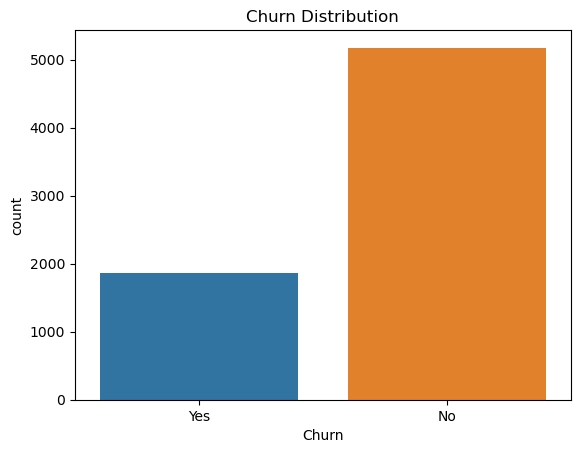

In [7]:
# Target variable balance
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='Churn')
plt.title('Churn Distribution')
plt.show()

### Initial Data Exploration Notes

We checked the dataset before doing anything else. There are no missing values, so the cleaning step for this dataset will be light. We did find 302 duplicate rows, so we will drop those in the next step.

We also looked at the target variable. Churn is imbalanced, with around 73% No and 27% Yes. We are noting this now because it will affect how we read the model's accuracy later. A model could score high on accuracy just by predicting "No" most of the time, so we will need to look at precision and recall too, not just accuracy, when we evaluate the ANN.

## 3.0 Clean the data

In [8]:
# Drop duplicate rows
print("Rows before dropping duplicates:", df.shape[0])
df = df.drop_duplicates()
print("Rows after dropping duplicates:", df.shape[0])

# Reset index after dropping rows
df = df.reset_index(drop=True)

# Double check there are no missing values left
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Rows before dropping duplicates: 7043
Rows after dropping duplicates: 6741

Missing values after cleaning:
gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64


## 4.0 Encode categorical variables

In [9]:
from sklearn.preprocessing import LabelEncoder

# Copy the dataframe so the original stays untouched
df_encoded = df.copy()

# Binary columns to label encode
binary_cols = ['gender', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'Churn']

le = LabelEncoder()
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])
    print(col, "classes:", list(le.classes_))

gender classes: ['Female', 'Male']
Dependents classes: ['No', 'Yes']
PhoneService classes: ['No', 'Yes']
MultipleLines classes: ['No', 'Yes']
InternetService classes: ['DSL', 'Fiber optic']
Churn classes: ['No', 'Yes']


In [10]:
# One-hot encode Contract, since it has more than two categories
df_encoded = pd.get_dummies(df_encoded, columns=['Contract'], drop_first=True)

df_encoded.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,MonthlyCharges,Churn,Contract_One year,Contract_Two year
0,0,0,0,1,0,0,0,25,1,0,0
1,1,0,0,41,1,0,0,25,0,1,0
2,0,0,1,52,1,0,0,19,0,0,0
3,0,0,0,1,1,0,0,76,1,1,0
4,1,0,0,67,1,0,1,51,0,0,0


### Data Cleaning and Encoding Notes

We dropped the 302 duplicate rows we found earlier and reset the index so the dataframe stays clean going forward. There were no missing values to handle, so that part was straightforward.

For the categorical columns, we split them into two groups. Gender, Dependents, PhoneService, MultipleLines, InternetService, and Churn are all binary, so we label encoded those as 0 and 1. We printed the classes for each column so we know exactly which value maps to which label, since label encoding assigns 0 and 1 alphabetically and we did not want to guess.

Contract has three categories (Month-to-month, One year, Two year) with no natural order between them, so we one-hot encoded that column instead of label encoding it. This avoids implying a ranking that does not exist in the data.

## 5.0 Feature scaling

In [11]:
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Identify numeric columns that need scaling
numeric_cols = ['tenure', 'MonthlyCharges']

scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

X.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,MonthlyCharges,Contract_One year,Contract_Two year
0,0,0,0,-1.312875,0,0,0,-1.376228,0,0
1,1,0,0,0.331038,1,0,0,-1.376228,1,0
2,0,0,1,0.783114,1,0,0,-1.578399,0,0
3,0,0,0,-1.312875,1,0,0,0.342225,1,0
4,1,0,0,1.399582,1,0,1,-0.500154,0,0


## 6.0 Train/test split

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\nChurn distribution in training set:")
print(y_train.value_counts(normalize=True))
print("\nChurn distribution in testing set:")
print(y_test.value_counts(normalize=True))

Training set shape: (5392, 10)
Testing set shape: (1349, 10)

Churn distribution in training set:
0    0.734236
1    0.265764
Name: Churn, dtype: float64

Churn distribution in testing set:
0    0.734618
1    0.265382
Name: Churn, dtype: float64


### Feature Scaling and Train/Test Split Notes

We scaled the numeric columns, tenure and MonthlyCharges, using StandardScaler. SeniorCitizen was already 0/1 so it did not need scaling. We scaled these because we are training a neural network later, and features on very different ranges can slow down or destabilise how the network converges.

We then split the data into training and testing sets, using 80% for training and 20% for testing. We used stratify=y in the split so the churn ratio stays roughly the same in both sets. Since churn is imbalanced in the full dataset, we wanted to avoid ending up with a test set that has too few churn cases to evaluate the model properly.

## 7.0 Elbow method and K-Means clustering

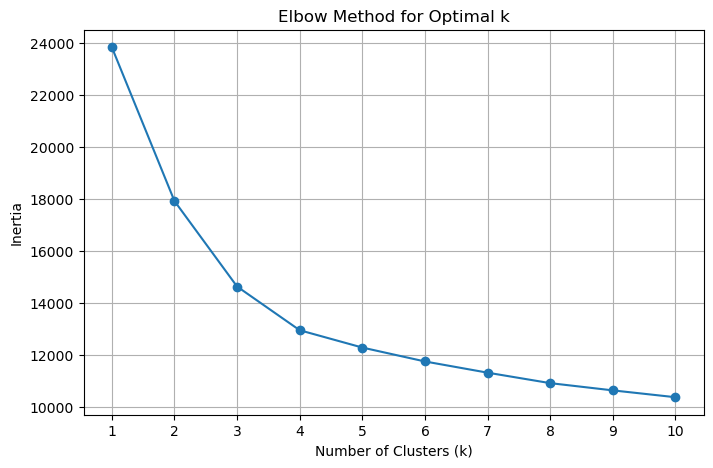

In [13]:
from sklearn.cluster import KMeans

# Use the scaled feature set for clustering
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(k_range)
plt.grid(True)
plt.show()

Looking at the plot, the drop is steep from k=1 to k=3, then it flattens out noticeably from k=4 onward. The elbow sits around k=4, that's where adding more clusters stops giving much reduction in inertia. 

## 7.1 Train final K-Means model and visualise clusters

In [14]:
# Train the final K-Means model with the chosen k
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X)

# Add the cluster labels back to a copy of the dataframe for interpretation
df_clustered = df_encoded.copy()
df_clustered['Cluster'] = cluster_labels

df_clustered['Cluster'].value_counts()

0    2149
2    1883
3    1585
1    1124
Name: Cluster, dtype: int64

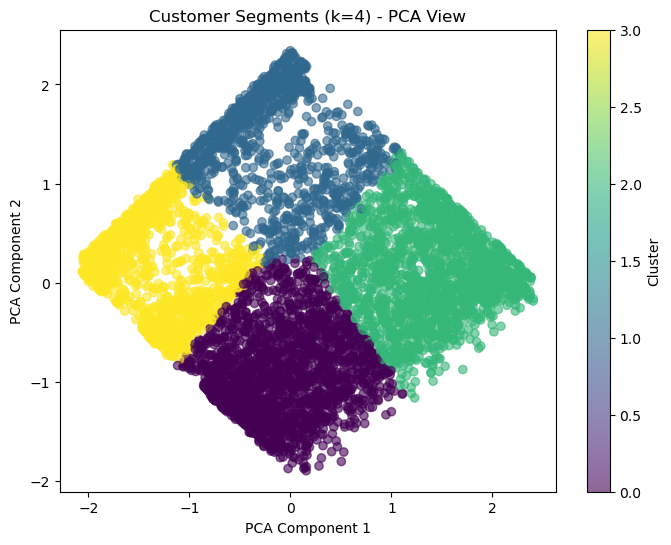

In [15]:
from sklearn.decomposition import PCA

# Reduce to 2 dimensions for visualisation only
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title(f'Customer Segments (k={optimal_k}) - PCA View')
plt.colorbar(scatter, label='Cluster')
plt.show()

In [16]:
# Interpret the clusters by looking at average feature values per cluster
cluster_summary = df_clustered.groupby('Cluster')[['tenure', 'MonthlyCharges', 'SeniorCitizen', 'Churn']].mean()
cluster_summary

,tenure,MonthlyCharges,SeniorCitizen,Churn
Cluster,,,,
0,15.195905,81.724058,0.243369,0.487669
1,54.333630,34.892349,0.077402,0.048043
2,58.714817,93.164100,0.215613,0.156134
3,11.227760,33.803785,0.071924,0.249211


### Clustering Notes

We used the elbow method to find the right number of clusters for K-Means. Looking at the inertia plot, the curve drops sharply up to around k=4, then flattens out, so we chose k=4 as the optimal number of clusters.

We trained the final K-Means model with k=4 and assigned each customer a cluster label. To visualise the clusters, we reduced the features to two dimensions using PCA, since we cannot plot the original feature space directly with more than two dimensions.

We also looked at the average tenure, monthly charges, senior citizen rate, and churn rate within each cluster. This let us describe each cluster in plain terms rather than just as a number, which will be useful when we bring these segments into the churn prediction discussion later.

### Cluster Interpretation Notes

We labelled the four clusters from the average tenure, monthly charges, senior citizen rate, and churn rate within each group. K-Means numbers its clusters in an arbitrary order that can change between computers, so the code assigns each label from the cluster averages, and these notes describe the segments by name instead of by cluster number.

High-risk new premium customers have short tenure (about 15 months on average), high monthly charges (about 82), and the highest churn rate of any segment at nearly 49%. This group also has the highest share of senior citizens at about 24%.

Loyal low-spend customers have long tenure (about 54 months), low monthly charges (about 35), and the lowest churn rate at under 5%.

Loyal high-value customers have the longest tenure (about 59 months) and the highest monthly charges (about 93). Their churn rate is moderate at about 15.6%, which matters because of how much revenue this group brings in.

New low-spend customers have the shortest tenure (about 11 months) and low monthly charges (about 34), with a moderate churn rate of about 24.9%.

These labels will be useful later when we compare the ANN's churn predictions against these segments, since the high-risk new premium segment looks like the group that retention strategies should prioritise.

## STAGE 2 DELIVERABLES

In [17]:
# Create the folders that match the submission structure
os.makedirs('Data_Preparation', exist_ok=True)
os.makedirs('Clustering_Analysis', exist_ok=True)

In [18]:
# Save the cleaned and encoded dataset
df_encoded.to_csv('Data_Preparation/preprocessed_dataset.csv', index=False)

print("Saved. Rows:", df_encoded.shape[0], "Columns:", df_encoded.shape[1])

Saved. Rows: 6741 Columns: 11


### Stage 2 Repository Setup Notes

We created two folders, Data_Preparation and Clustering_Analysis, matching the structure required for the Stage 2 submission. This keeps the data preparation deliverables separate from the clustering deliverables, so they are easy for the instructor to find and review.

We saved the cleaned and encoded dataset as preprocessed_dataset.csv inside the Data_Preparation folder. This is the version of the data after we dropped duplicates, label encoded the binary columns, and one-hot encoded Contract. It has 6741  rows and 11 columns.

In [19]:
# Save the training and testing sets
X_train.to_csv('Data_Preparation/X_train.csv', index=False)
X_test.to_csv('Data_Preparation/X_test.csv', index=False)
y_train.to_csv('Data_Preparation/y_train.csv', index=False)
y_test.to_csv('Data_Preparation/y_test.csv', index=False)

print("Training set:", X_train.shape[0], "rows,", X_train.shape[1], "features")
print("Testing set:", X_test.shape[0], "rows,", X_test.shape[1], "features")
print("\nChurn distribution in training set:")
print(y_train.value_counts(normalize=True).round(3))
print("\nChurn distribution in testing set:")
print(y_test.value_counts(normalize=True).round(3))

Training set: 5392 rows, 10 features
Testing set: 1349 rows, 10 features

Churn distribution in training set:
0    0.734
1    0.266
Name: Churn, dtype: float64

Churn distribution in testing set:
0    0.735
1    0.265
Name: Churn, dtype: float64


### Training and Testing Set Notes

We saved the training and testing sets as separate CSV files inside the Data_Preparation folder, X_train.csv and X_test.csv for the features, and y_train.csv and y_test.csv for the target.

The training set has 5392 rows and the testing set has 1349 rows, an 80/20 split. We used stratify=y when splitting, so the churn ratio stayed close to 73.5% No and 26.5% Yes in both sets. This matters because churn is imbalanced in the full dataset, and stratifying avoids ending up with a test set that has too few churn cases to evaluate the model fairly.

## Save the trained K-Means model

In [20]:
import joblib

# Save the trained K-Means model so it can be reloaded without retraining
joblib.dump(kmeans_final, 'Clustering_Analysis/kmeans_model.pkl')

print("Model saved.")

Model saved.


In [21]:
# Quick check that the saved model loads and works correctly
loaded_model = joblib.load('Clustering_Analysis/kmeans_model.pkl')
print("Cluster centers shape:", loaded_model.cluster_centers_.shape)

Cluster centers shape: (4, 10)


### K-Means Model File Notes

We saved the trained K-Means model as kmeans_model.pkl inside the Clustering_Analysis folder, using joblib. This lets the model be reloaded later without retraining, and satisfies the Stage 2 requirement to include the trained model file alongside the clustering scripts.

We also reloaded the saved model to confirm it works correctly before including it in the submission.

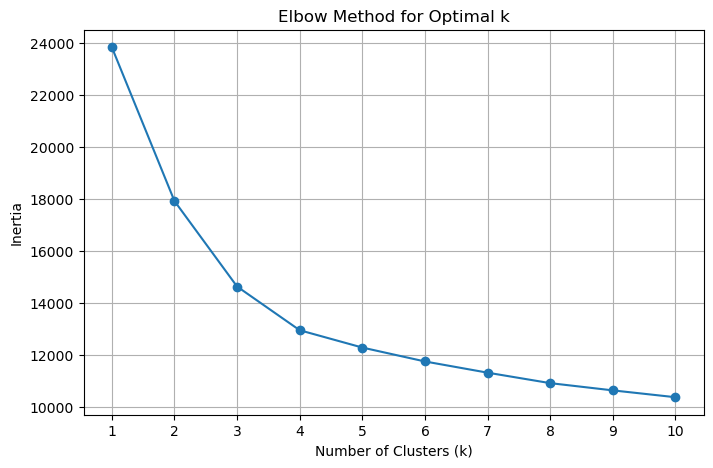

In [22]:
# Save the elbow plot as an image file for the documentation
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(list(k_range))
plt.grid(True)
plt.savefig('Clustering_Analysis/elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()

### Optimal Number of Clusters Notes

We saved the elbow method plot as elbow_method.png inside the Clustering_Analysis folder. This is the supporting visualisation for how we chose k=4 as the optimal number of clusters, showing a steep drop in inertia up to k=4 followed by a flattening curve.

## Save the cluster visualisation and labelled cluster summary

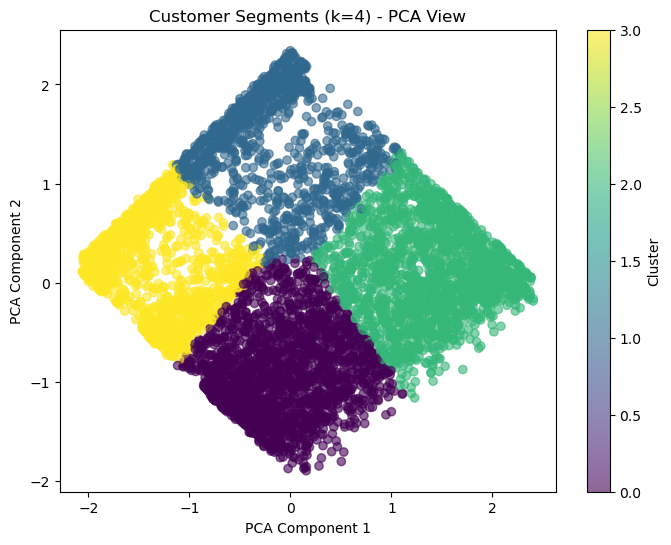

In [23]:
# Save the PCA cluster visualisation
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title(f'Customer Segments (k={optimal_k}) - PCA View')
plt.colorbar(scatter, label='Cluster')
plt.savefig('Clustering_Analysis/cluster_visualisation.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
# Save the dataset with cluster labels attached
df_clustered.to_csv('Clustering_Analysis/clustered_dataset.csv', index=False)

# Save the cluster summary table (average feature values per cluster)
cluster_summary.to_csv('Clustering_Analysis/cluster_summary.csv')

print(cluster_summary)

            tenure  MonthlyCharges  SeniorCitizen     Churn
Cluster                                                    
0        15.195905       81.724058       0.243369  0.487669
1        54.333630       34.892349       0.077402  0.048043
2        58.714817       93.164100       0.215613  0.156134
3        11.227760       33.803785       0.071924  0.249211


In [25]:
# Label each cluster from its own averages, so the labels do not depend on how K-Means happens to number the clusters.
# Clusters with above-median tenure are 'loyal', clusters with above-median monthly charges are 'high spend'.
tenure_cut = cluster_summary['tenure'].median()
charge_cut = cluster_summary['MonthlyCharges'].median()

def label_cluster(row):
    long_tenure = row['tenure'] > tenure_cut
    high_charge = row['MonthlyCharges'] > charge_cut
    if long_tenure and high_charge:
        return "Loyal high-value customers"
    if long_tenure and not high_charge:
        return "Loyal low-spend customers"
    if high_charge:
        return "High-risk new premium customers"
    return "New low-spend customers"

cluster_labels_map = cluster_summary.apply(label_cluster, axis=1).to_dict()

# Each of the four segments must appear exactly once
assert len(set(cluster_labels_map.values())) == 4, "Two clusters received the same label, check cluster_summary"

df_clustered['Cluster_Label'] = df_clustered['Cluster'].map(cluster_labels_map)
df_clustered.to_csv('Clustering_Analysis/clustered_dataset.csv', index=False)

# Save the summary again, this time with the label next to each cluster
cluster_summary_labelled = cluster_summary.copy()
cluster_summary_labelled['Label'] = cluster_summary_labelled.index.map(cluster_labels_map)
cluster_summary_labelled.to_csv('Clustering_Analysis/cluster_summary.csv')

cluster_summary_labelled.round(3)

,tenure,MonthlyCharges,SeniorCitizen,Churn,Label
Cluster,,,,,
0,15.196,81.724,0.243,0.488,High-risk new premium customers
1,54.334,34.892,0.077,0.048,Loyal low-spend customers
2,58.715,93.164,0.216,0.156,Loyal high-value customers
3,11.228,33.804,0.072,0.249,New low-spend customers


### Cluster Visualisation and Labelling Notes

We saved the PCA scatter plot as cluster_visualisation.png inside the Clustering_Analysis folder. Since the feature space has more than two dimensions, we used PCA to reduce it to two components purely for visualisation, so the four clusters could be plotted and inspected visually.

We also saved the clustered dataset (clustered_dataset.csv) and a summary table of average feature values per cluster (cluster_summary.csv). Based on tenure, monthly charges, senior citizen rate, and churn rate, we labelled the clusters in plain terms as high-risk new premium customers, loyal low-spend customers, loyal high-value customers, and new low-spend customers. These labels make the segments easier to interpret and will support the retention strategy recommendations later.

The labels are assigned in code from each cluster's average tenure and monthly charges, so they stay correct even if K-Means numbers the clusters in a different order on another computer.

## 8.0 Define the ANN architecture

In [26]:
set_seed()
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Check the number of input features
print("Number of input features:", X_train.shape[1])

# Build the ANN
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

Number of input features: 10


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

### ANN Architecture Notes

We defined the ANN as a sequential model with two hidden layers, the first with 16 neurons and the second with 8 neurons, both using ReLU activation. ReLU is a standard choice for hidden layers in this kind of task and helps the network train efficiently.

The output layer has a single neuron with a sigmoid activation, since this is a binary classification problem. Sigmoid outputs a probability between 0 and 1, which we can then interpret as the likelihood of a customer churning.

We compiled the model with the Adam optimiser and binary crossentropy loss, since binary crossentropy is the standard loss function for a binary classification problem like this one, and we tracked accuracy as our initial evaluation metric.

## 9.0 Train the baseline model

In [28]:
set_seed()
# Train the baseline model
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7407 - loss: 0.5539 - val_accuracy: 0.7776 - val_loss: 0.4873
Epoch 2/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7839 - loss: 0.4785 - val_accuracy: 0.7813 - val_loss: 0.4707
Epoch 3/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7829 - loss: 0.4604 - val_accuracy: 0.7794 - val_loss: 0.4654
Epoch 4/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7889 - loss: 0.4532 - val_accuracy: 0.7776 - val_loss: 0.4626
Epoch 5/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7932 - loss: 0.4497 - val_accuracy: 0.7776 - val_loss: 0.4603
Epoch 6/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7982 - loss: 0.4469 - val_accuracy: 0.7813 - val_loss: 0.4583
Epoch 7/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7993 - loss: 0.4447 - val_accuracy: 0.7831 - val_loss: 0.4570
Epoch 8/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8000 - loss: 0.4433 - val_accuracy: 0.

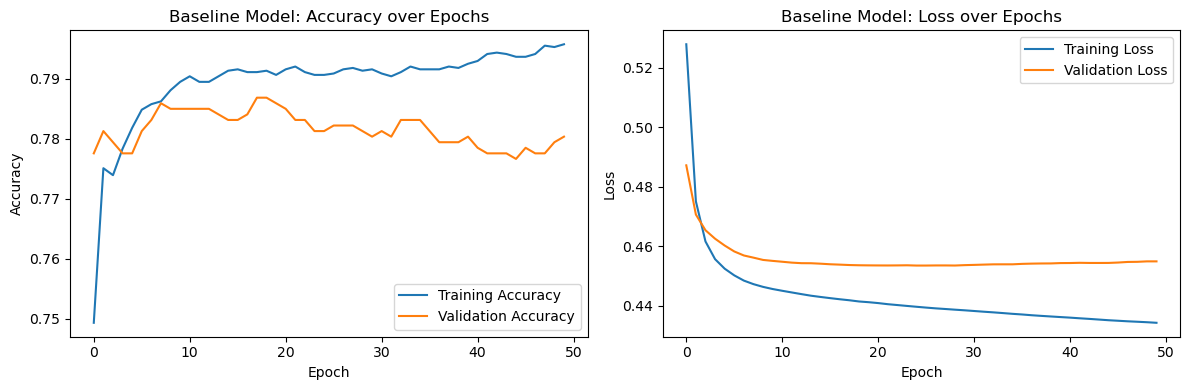

In [29]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Baseline Model: Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Baseline Model: Loss over Epochs')
plt.legend()

plt.tight_layout()
plt.savefig('baseline_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Baseline Model Training Notes

We trained the ANN using a baseline configuration, 50 epochs, a batch size of 32, and the Adam optimiser at its default learning rate. We held out 20% of the training data as a validation set to monitor performance on unseen data during training.

Training accuracy rose steadily to about 80% by epoch 50. Validation accuracy peaked at about 78.7% around epoch 18 and then drifted down to about 78.0%. The loss curves showed the same pattern. Validation loss reached its lowest point of about 0.454 near epoch 20 and then crept up slightly to about 0.455, while training loss kept falling to about 0.433. This growing gap between training and validation results is a sign of mild overfitting. The model kept fitting the training data more closely without getting better on unseen data.

This tells us two things for the tuning step. First, 50 epochs is more than the model needs, since validation performance stopped improving at around epoch 20. Second, we should try techniques that reduce overfitting, such as dropout and early stopping.

## 10.0 Hyperparameter tuning

In [30]:
set_seed()
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dropout

# Rebuild the model with dropout added to reduce overfitting
model_tuned = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(8, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

model_tuned.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_tuned.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 16)                  │             176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 8)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
set_seed()
# Early stopping so training halts once validation loss stops improving,
# and restores the best weights rather than the last epoch's weights
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_tuned = model_tuned.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6484 - loss: 0.6365 - val_accuracy: 0.7424 - val_loss: 0.5119
Epoch 2/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7391 - loss: 0.5308 - val_accuracy: 0.7748 - val_loss: 0.4746
Epoch 3/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7620 - loss: 0.4989 - val_accuracy: 0.7859 - val_loss: 0.4671
Epoch 4/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7583 - loss: 0.4944 - val_accuracy: 0.7813 - val_loss: 0.4640
Epoch 5/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7658 - loss: 0.4774 - val_accuracy: 0.7776 - val_loss: 0.4627
Epoch 6/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7752 - loss: 0.4767 - val_accuracy: 0.7794 - val_loss: 0.4614
Epoch 7/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7689 - loss: 0.4802 - val_accuracy: 0.7841 - val_loss: 0.4615
Epoch 8/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7679 - loss: 0.4764 - val_accu

135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7982 - loss: 0.4499 - val_accuracy: 0.7905 - val_loss: 0.4492
Epoch 52/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7896 - loss: 0.4534 - val_accuracy: 0.7933 - val_loss: 0.4497


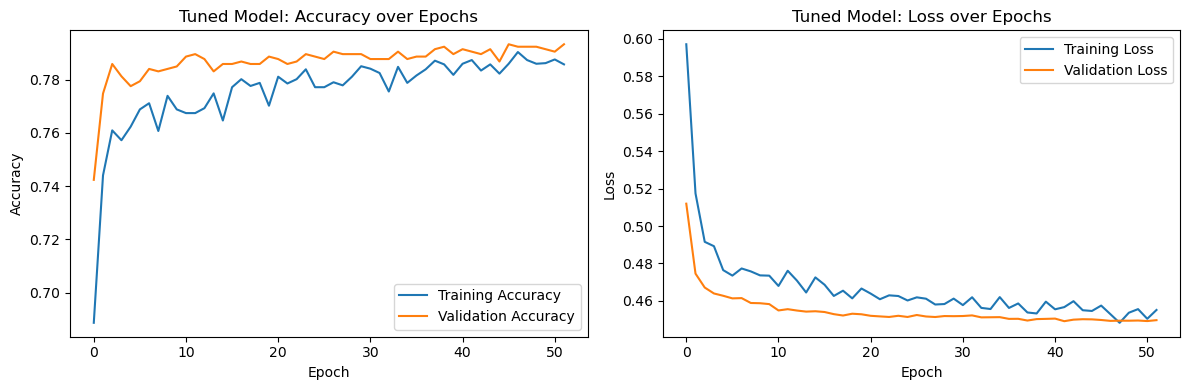

In [32]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['accuracy'], label='Training Accuracy')
plt.plot(history_tuned.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Tuned Model: Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['loss'], label='Training Loss')
plt.plot(history_tuned.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Tuned Model: Loss over Epochs')
plt.legend()

plt.tight_layout()
plt.savefig('tuned_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Hyperparameter Tuning Notes

To address the mild overfitting seen in the baseline model, we made two changes. We added dropout layers (0.3 after the first hidden layer, 0.2 after the second) to reduce the model's tendency to memorise the training data. We also added early stopping, which monitors validation loss with a patience of 10 epochs, stops training once validation performance stops improving, and restores the weights from the best epoch instead of the last one. We kept the learning rate at the Adam default of 0.001, since the baseline problem was overfitting and not slow learning.

Training stopped by itself after 52 epochs, and the best weights came from epoch 42. The curves behave differently from the baseline. Validation accuracy levelled off at about 79%, a little above the baseline's best of about 78.7%, and the lowest validation loss was about 0.449, compared with about 0.454 for the baseline. Training accuracy sits slightly below validation accuracy, at about 78 to 79% by the end. This is normal with dropout, because dropout is switched on while training and switched off when validating. The gap between training and validation loss did not widen over time.

We are proceeding with this tuned model, since it converges more reliably and shows no sign of overfitting. The gain in headline accuracy over the baseline is small.

## 11.0 Evaluate the tuned model on the test set

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Get predictions on the test set
y_pred_proba = model_tuned.predict(X_test)
y_pred = (y_pred_proba > 0.5).astype(int)

# Core metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("\nFull classification report:")
print(classification_report(y_test, y_pred))

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.7902149740548554
Precision: 0.6482213438735178
Recall: 0.4581005586592179
F1 Score: 0.5368248772504092

Full classification report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       991
           1       0.65      0.46      0.54       358

    accuracy                           0.79      1349
   macro avg       0.74      0.68      0.70      1349
weighted avg       0.78      0.79      0.78      1349



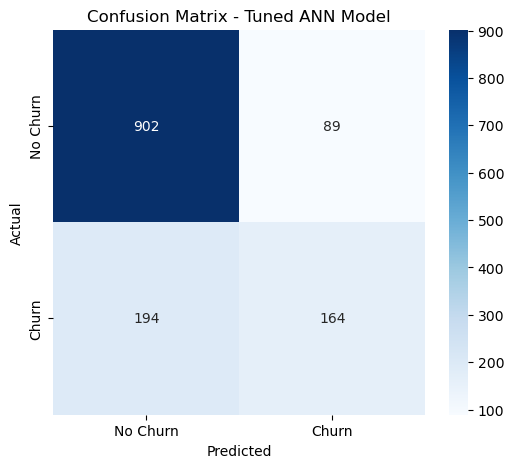

In [34]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Tuned ANN Model')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### Model Evaluation Notes

We evaluated the tuned ANN model on the held-out test set. Overall accuracy was 79%, but since churn is the minority class in our dataset, we looked past accuracy to precision, recall, and F1 score for the churn class specifically.

For the churn class, precision was 0.65, recall was 0.46, and F1 score was 0.54. The confusion matrix showed the model correctly identified 164 of the 358 actual churners in the test set, and missed 194 of them by classifying them as non-churners. 

This recall level is a limitation worth addressing. In a churn prediction context, a false negative, a customer who churns but is predicted not to, is generally more costly than a false positive, since a missed churner is a customer the business never gets the chance to try to retain. A recall of 46% means the model currently misses more churners than it catches, so in the next step we use class weighting during training to improve this, and later we check whether adjusting the classification threshold helps.

## 12.0 Improve recall with class weighting

In [35]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Compute class weights so the model penalises missing a churner more heavily during training
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)

Class weights: {0: 0.6809800454660268, 1: 1.8813677599441732}


In [36]:
set_seed()
# Rebuild and retrain with class weighting applied
model_weighted = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(8, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

model_weighted.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_weighted = model_weighted.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5613 - loss: 0.7139 - val_accuracy: 0.6376 - val_loss: 0.6438
Epoch 2/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6393 - loss: 0.6374 - val_accuracy: 0.6979 - val_loss: 0.5745
Epoch 3/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6717 - loss: 0.5933 - val_accuracy: 0.6858 - val_loss: 0.5677
Epoch 4/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6934 - loss: 0.5855 - val_accuracy: 0.6969 - val_loss: 0.5542
Epoch 5/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7078 - loss: 0.5646 - val_accuracy: 0.6914 - val_loss: 0.5552
Epoch 6/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6926 - loss: 0.5594 - val_accuracy: 0.6923 - val_loss: 0.5530
Epoch 7/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6998 - loss: 0.5686 - val_accuracy: 0.6895 - val_loss: 0.5608
Epoch 8/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6950 - loss: 0.5657 - val_accu

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.7316530763528539
Precision: 0.4964788732394366
Recall: 0.7877094972067039
F1 Score: 0.6090712742980562

               precision    recall  f1-score   support

           0       0.90      0.71      0.80       991
           1       0.50      0.79      0.61       358

    accuracy                           0.73      1349
   macro avg       0.70      0.75      0.70      1349
weighted avg       0.79      0.73      0.75      1349



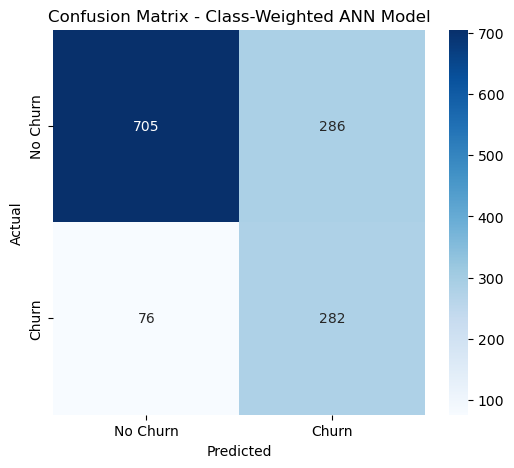

In [37]:
# Evaluate again with the same 0.5 threshold first, to isolate the effect of class weighting
y_pred_proba_weighted = model_weighted.predict(X_test)
y_pred_weighted = (y_pred_proba_weighted > 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_weighted))
print("Precision:", precision_score(y_test, y_pred_weighted))
print("Recall:", recall_score(y_test, y_pred_weighted))
print("F1 Score:", f1_score(y_test, y_pred_weighted))
print("\n", classification_report(y_test, y_pred_weighted))

cm_weighted = confusion_matrix(y_test, y_pred_weighted)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_weighted, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Class-Weighted ANN Model')
plt.savefig('confusion_matrix_weighted.png', dpi=150, bbox_inches='tight')
plt.show()

### Class Weighting Results and Model Selection

We retrained the model with class weighting applied, so the loss function penalises misclassifying the minority class (churners) more heavily during training. We evaluated it on the test set using the same 0.5 threshold as before, to isolate the effect of class weighting alone.

The results showed a clear trade-off. Accuracy dropped from 79% to 73%, and precision for the churn class dropped from 0.65 to 0.50. However, recall for the churn class rose sharply from 0.46 to 0.79, and F1 score improved from 0.54 to 0.61. In practical terms, the class-weighted model correctly identified 282 of the 358 actual churners in the test set, compared with 164 for the unweighted model. That cut the number of missed churners from 194 to 76, at the cost of more false alarms, 286 compared with 89.

In a churn prediction context, a missed churner is more costly than a false alarm, since a missed churner is a customer the business loses entirely, while a false positive only costs an unnecessary retention offer to a customer who was going to stay anyway. Given this asymmetry, and the fact that F1 score also improved overall, prioritising recall is the right choice for this use case, not just a statistical trade-off but a business-aligned one.

## 13.0 Threshold tuning

In [38]:
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score

# Get precision, recall, and thresholds across the full range
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba_weighted)

# Compute F1 at each threshold to find the best one
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Best threshold for F1:", best_threshold)
print("Precision at best threshold:", precisions[best_idx])
print("Recall at best threshold:", recalls[best_idx])
print("F1 at best threshold:", f1_scores[best_idx])

Best threshold for F1: 0.51873314
Precision at best threshold: 0.5091575091575091
Recall at best threshold: 0.776536312849162
F1 at best threshold: 0.6150442477397731


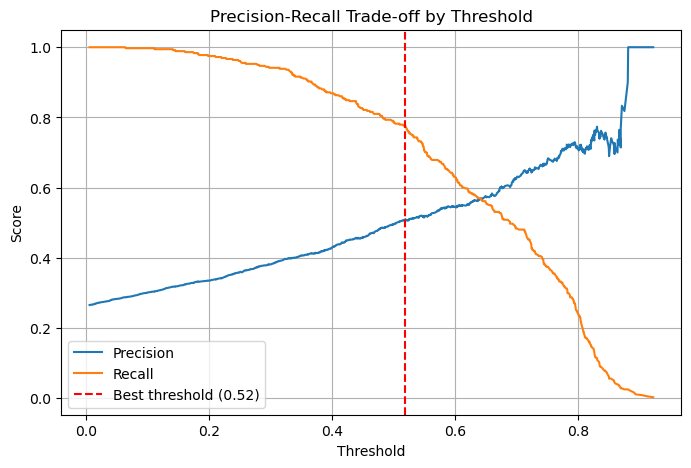

In [39]:
# Plot precision and recall against threshold to see the trade-off visually
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.axvline(x=best_threshold, color='red', linestyle='--', label=f'Best threshold ({best_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off by Threshold')
plt.legend()
plt.grid(True)
plt.savefig('threshold_tuning.png', dpi=150, bbox_inches='tight')
plt.show()

Accuracy: 0.7412898443291327
Precision: 0.5082568807339449
Recall: 0.7737430167597765
F1 Score: 0.6135105204872646

               precision    recall  f1-score   support

           0       0.90      0.73      0.81       991
           1       0.51      0.77      0.61       358

    accuracy                           0.74      1349
   macro avg       0.70      0.75      0.71      1349
weighted avg       0.80      0.74      0.75      1349



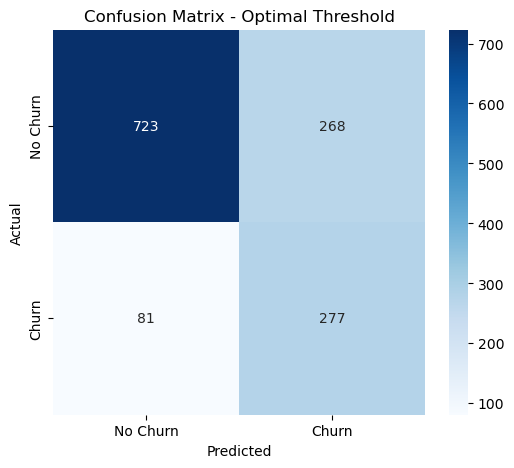

In [40]:
# Evaluate using the best threshold instead of the default 0.5
y_pred_optimal = (y_pred_proba_weighted > best_threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_optimal))
print("Precision:", precision_score(y_test, y_pred_optimal))
print("Recall:", recall_score(y_test, y_pred_optimal))
print("F1 Score:", f1_score(y_test, y_pred_optimal))
print("\n", classification_report(y_test, y_pred_optimal))

cm_optimal = confusion_matrix(y_test, y_pred_optimal)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_optimal, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Optimal Threshold')
plt.savefig('confusion_matrix_optimal_threshold.png', dpi=150, bbox_inches='tight')
plt.show()

ROC-AUC Score: 0.8193067213863318


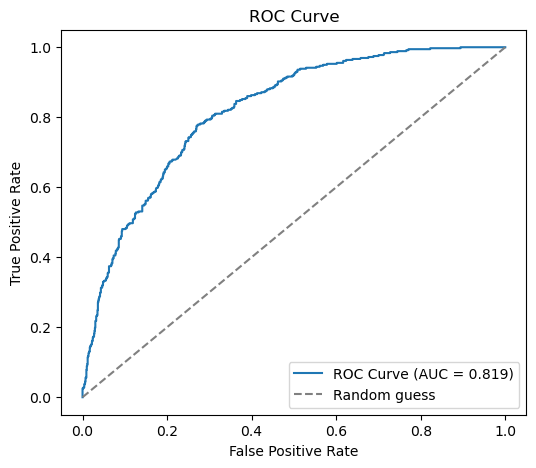

In [41]:
auc = roc_auc_score(y_test, y_pred_proba_weighted)
print("ROC-AUC Score:", auc)

fpr, tpr, _ = roc_curve(y_test, y_pred_proba_weighted)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

### Threshold Tuning and ROC-AUC Notes

We tested whether moving the classification threshold away from the default 0.5 could improve on the class-weighted model. We calculated precision and recall across the full range of thresholds and found the threshold that maximises F1 score.

The best threshold was about 0.52, close to the default. At that threshold recall was 0.77 and F1 was 0.61, compared with recall of 0.79 and F1 of 0.61 at 0.5. The gain was tiny (F1 up by about 0.005) and it came with slightly lower recall. We also found this threshold using the same test set that we report on, so any gain is slightly optimistic. Given all this, we keep the default 0.5 threshold.

We also calculated the ROC-AUC score for the class-weighted model, which was 0.819. This measures how well the model separates churners from non-churners across all possible thresholds, and a score above 0.8 indicates good discriminative performance.

### Interim Model Summary Before Grid Search

At this point the class-weighted ANN (model_weighted) was our best model, and we used it as the reference to compare against the grid search model in the next sections. It uses the default 0.5 classification threshold.

**Architecture**

The model is a sequential neural network with two hidden layers, 16 neurons in the first and 8 in the second, both using ReLU activation. Dropout of 0.3 follows the first hidden layer and 0.2 follows the second, to reduce overfitting. The output layer has a single neuron with sigmoid activation, giving a churn probability between 0 and 1. We compiled it with the Adam optimiser at a learning rate of 0.001 and binary crossentropy loss, and trained it with a batch size of 32, class weighting, and early stopping.

**How we got here**

We started with a baseline model trained for 50 fixed epochs. It reached about 80% training accuracy, but validation accuracy peaked at about 78.7% around epoch 18 and then drifted down, and the gap between training and validation loss slowly widened. This told us the model was mildly overfitting.

To address this, we added dropout layers and early stopping. Training stopped by itself after 52 epochs with the best weights from epoch 42, and validation accuracy levelled off at about 79%.

When we evaluated this tuned model on the test set, overall accuracy was 79%, but recall on the churn class was only 46%. Out of 358 actual churners, the model missed 194. Because churn is imbalanced in this dataset, accuracy was hiding a real weakness, since the model was much better at recognising loyal customers than at catching customers who were about to leave.

To fix this, we applied class weighting during training so the loss function penalises missing churners more heavily. This raised recall for the churn class from 0.46 to 0.79 and F1 from 0.54 to 0.61. The model correctly identified 282 of the 358 churners and missed 76, compared with 194 missed before. The trade-off was more false alarms, 286 compared with 89, and lower accuracy, 73% compared with 79%.

We accepted this trade-off deliberately. A missed churner is a customer the business loses with no chance to intervene, while a false alarm only costs an unnecessary retention offer to a customer who was going to stay anyway.

**Threshold check**

The F1-optimal threshold was about 0.52, close to the default with only a tiny gain, so we kept 0.5.

**Metrics on the test set**

| Metric | Value |
|---|---|
| Accuracy | 0.732 |
| Precision (Churn) | 0.496 |
| Recall (Churn) | 0.788 |
| F1 Score (Churn) | 0.609 |
| ROC-AUC | 0.819 |

We then ran a grid search to check whether different settings could do better.

## 14.0 Grid search for hyperparameters

In [42]:
import itertools
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score
from tensorflow.keras.callbacks import EarlyStopping

# Split off a validation set from the training data only
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Class weights computed on the smaller training portion
cw = compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
cw_dict = dict(enumerate(cw))

# Small grid, 16 combinations
grid = {
    'units': [(16, 8), (32, 16)],
    'dropout': [0.2, 0.3],
    'lr': [0.001, 0.0005],
    'batch_size': [32, 64],
}

results = []

for units, dropout, lr, batch_size in itertools.product(
    grid['units'], grid['dropout'], grid['lr'], grid['batch_size']
):
    keras.backend.clear_session()
    set_seed()

    m = keras.Sequential([
        layers.Input(shape=(X_tr.shape[1],)),
        layers.Dense(units[0], activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(units[1], activation='relu'),
        layers.Dropout(dropout - 0.1),
        layers.Dense(1, activation='sigmoid')
    ])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss='binary_crossentropy', metrics=['accuracy'])

    m.fit(X_tr, y_tr,
          validation_data=(X_val, y_val),
          epochs=100, batch_size=batch_size,
          class_weight=cw_dict,
          callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
          verbose=0)

    val_pred = (m.predict(X_val, verbose=0) > 0.5).astype(int)
    results.append({
        'units': units, 'dropout': dropout, 'lr': lr, 'batch_size': batch_size,
        'val_recall': recall_score(y_val, val_pred),
        'val_f1': f1_score(y_val, val_pred)
    })
    print(f"Done: {units}, dropout={dropout}, lr={lr}, batch={batch_size}")

results_df = pd.DataFrame(results).sort_values('val_f1', ascending=False)
results_df


Done: (16, 8), dropout=0.2, lr=0.001, batch=32
Done: (16, 8), dropout=0.2, lr=0.001, batch=64
Done: (16, 8), dropout=0.2, lr=0.0005, batch=32
Done: (16, 8), dropout=0.2, lr=0.0005, batch=64
Done: (16, 8), dropout=0.3, lr=0.001, batch=32
Done: (16, 8), dropout=0.3, lr=0.001, batch=64
Done: (16, 8), dropout=0.3, lr=0.0005, batch=32
Done: (16, 8), dropout=0.3, lr=0.0005, batch=64
Done: (32, 16), dropout=0.2, lr=0.001, batch=32
Done: (32, 16), dropout=0.2, lr=0.001, batch=64
Done: (32, 16), dropout=0.2, lr=0.0005, batch=32
Done: (32, 16), dropout=0.2, lr=0.0005, batch=64
Done: (32, 16), dropout=0.3, lr=0.001, batch=32
Done: (32, 16), dropout=0.3, lr=0.001, batch=64
Done: (32, 16), dropout=0.3, lr=0.0005, batch=32
Done: (32, 16), dropout=0.3, lr=0.0005, batch=64


,units,dropout,lr,batch_size,val_recall,val_f1
7,"(16, 8)",0.3,0.0005,64,0.797909,0.601050
5,"(16, 8)",0.3,0.0010,64,0.797909,0.599476
1,"(16, 8)",0.2,0.0010,64,0.780488,0.596538
6,"(16, 8)",0.3,0.0005,32,0.777003,0.593085
4,"(16, 8)",0.3,0.0010,32,0.773519,0.589641
2,"(16, 8)",0.2,0.0005,32,0.759582,0.588394
0,"(16, 8)",0.2,0.0010,32,0.752613,0.587755
8,"(32, 16)",0.2,0.0010,32,0.728223,0.585434
3,"(16, 8)",0.2,0.0005,64,0.752613,0.585366
13,"(32, 16)",0.3,0.0010,64,0.724739,0.583450


In [43]:
# Save the results table for your documentation
results_df.to_csv('grid_search_results.csv', index=False)
results_df.head()

,units,dropout,lr,batch_size,val_recall,val_f1
7,"(16, 8)",0.3,0.0005,64,0.797909,0.601050
5,"(16, 8)",0.3,0.0010,64,0.797909,0.599476
1,"(16, 8)",0.2,0.0010,64,0.780488,0.596538
6,"(16, 8)",0.3,0.0005,32,0.777003,0.593085
4,"(16, 8)",0.3,0.0010,32,0.773519,0.589641


### Grid Search Notes

Our earlier tuning was manual. We diagnosed overfitting from the baseline curves and responded with dropout, early stopping, and class weighting. To check that our settings were sensible, we also ran a small grid search over four hyperparameters. We tried two layer sizes (16 and 8, or 32 and 16), two dropout levels (0.2 and 0.3), two learning rates (0.001 and 0.0005), and two batch sizes (32 and 64), which gave 16 combinations in total.

To avoid leaking information from the test set, we ran the search on a validation split taken from the training data only. Every configuration used class weighting and early stopping, and we ranked them by validation F1 score for the churn class, since balancing recall and precision on churners matters most for this problem.

The best configuration used 16 and 8 neurons, dropout of 0.3 (and 0.2 in the second layer), a learning rate of 0.0005, and a batch size of 64. It reached a validation recall of 0.80 and a validation F1 of 0.601. The next four configurations scored between 0.590 and 0.599 on F1. Across all 16 configurations, F1 only ranged from 0.577 to 0.601, and the smaller 16 and 8 networks scored slightly higher than the larger 32 and 16 networks. The settings we had picked by hand (16 and 8 neurons, dropout of 0.3, learning rate 0.001, batch size 32) scored 0.590, which ranked fifth.

These differences are very small. So we treat the winning configuration as a candidate and not a firm result, and the main message from the search is that the model is not very sensitive to these settings. The bigger gains in this project came from dealing with overfitting and class imbalance. In the next step we retrain the winning configuration on the full training set and compare it with the class-weighted model on the test set.

## 15.0 Retrain the best configuration and compare it with the class-weighted model

In [44]:
keras.backend.clear_session()
set_seed()

# Best configuration from the grid search, read straight from the results table
best = results_df.iloc[0]
best_units = best['units']
best_dropout = best['dropout']
best_lr = best['lr']
best_batch = int(best['batch_size'])
print("Best configuration from the grid search")
print("Layer sizes:", best_units, "| Dropout:", best_dropout, "| Learning rate:", best_lr, "| Batch size:", best_batch)

model_best = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(best_units[0], activation='relu'),
    layers.Dropout(best_dropout),
    layers.Dense(best_units[1], activation='relu'),
    layers.Dropout(best_dropout - 0.1),
    layers.Dense(1, activation='sigmoid')
])

model_best.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_lr),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_best = model_best.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=best_batch,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Best configuration from the grid search
Layer sizes: (16, 8) | Dropout: 0.3 | Learning rate: 0.0005 | Batch size: 64
Epoch 1/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5468 - loss: 0.7354 - val_accuracy: 0.5616 - val_loss: 0.6852
Epoch 2/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5777 - loss: 0.7014 - val_accuracy: 0.5839 - val_loss: 0.6712
Epoch 3/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6067 - loss: 0.6694 - val_accuracy: 0.6562 - val_loss: 0.6427
Epoch 4/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6433 - loss: 0.6495 - val_accuracy: 0.6923 - val_loss: 0.6176
Epoch 5/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6608 - loss: 0.6288 - val_accuracy: 0.7006 - val_loss: 0.5911
Epoch 6/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6740 - loss: 0.6041 - val_accuracy: 0.6997 - val_loss: 0.5720
Epoch 7/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6818 - loss: 0.5934 - val_accuracy: 0.6886 - val_loss: 0

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       0.91      0.68      0.78       991
           1       0.48      0.80      0.60       358

    accuracy                           0.72      1349
   macro avg       0.69      0.74      0.69      1349
weighted avg       0.79      0.72      0.73      1349

ROC-AUC: 0.8156241367841298


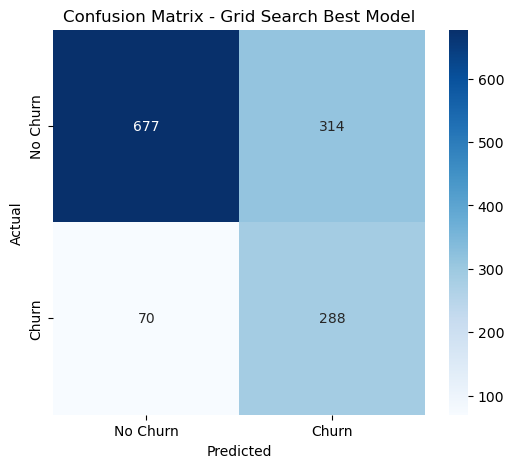

In [45]:
# Evaluate on the test set
y_pred_proba_best = model_best.predict(X_test)
y_pred_best = (y_pred_proba_best > 0.5).astype(int)

print(classification_report(y_test, y_pred_best))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba_best))

cm_best = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Grid Search Best Model')
plt.savefig('confusion_matrix_grid_best.png', dpi=150, bbox_inches='tight')
plt.show()

In [46]:
# Side by side comparison with the current final model
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Churn)', 'Recall (Churn)', 'F1 (Churn)', 'ROC-AUC'],
    'Current final model': [
        accuracy_score(y_test, y_pred_weighted),
        precision_score(y_test, y_pred_weighted),
        recall_score(y_test, y_pred_weighted),
        f1_score(y_test, y_pred_weighted),
        roc_auc_score(y_test, y_pred_proba_weighted)
    ],
    'Grid search best model': [
        accuracy_score(y_test, y_pred_best),
        precision_score(y_test, y_pred_best),
        recall_score(y_test, y_pred_best),
        f1_score(y_test, y_pred_best),
        roc_auc_score(y_test, y_pred_proba_best)
    ]
}).round(3)

comparison

,Metric,Current final model,Grid search best model
0,Accuracy,0.732,0.715
1,Precision (Churn),0.496,0.478
2,Recall (Churn),0.788,0.804
3,F1 (Churn),0.609,0.600
4,ROC-AUC,0.819,0.816


### Grid Search Model Comparison Notes

We retrained the best grid search configuration (16 and 8 neurons, dropout of 0.3 and 0.2, learning rate of 0.0005, batch size of 64) on the full training set, using class weighting and early stopping as before. We evaluated it once on the test set and compared it with the class-weighted model from earlier.

The two models are very close, and neither is better on every metric.

| Metric | Class-weighted model | Grid search model |
|---|---|---|
| Accuracy | 0.732 | 0.715 |
| Precision (Churn) | 0.496 | 0.478 |
| Recall (Churn) | 0.788 | 0.804 |
| F1 (Churn) | 0.609 | 0.600 |
| ROC-AUC | 0.819 | 0.816 |
| Churners caught (of 358) | 282 | 288 |
| False alarms | 286 | 314 |

The grid search model has slightly higher recall and catches 6 more churners, while the class-weighted model is slightly higher on accuracy, precision, F1 and ROC-AUC, and raises fewer false alarms. All of these gaps are small, about 0.02 or less, and are small enough that we would not read much into them.

We are keeping the grid search model as our final model. It was chosen through a systematic search that used validation data and not the test set, and it catches slightly more churners, which matches our priority of finding as many churners as possible. We do not claim it is better overall. The class-weighted model is an equally reasonable choice, and the difference between them is small. We saved the final model as churn_ann_model_final.keras.

## 16.0 Save the final model and link its predictions to the clusters

In [47]:
# Save the final model
model_best.save('churn_ann_model_final.keras')
print("Final model saved.")

Final model saved.


In [48]:
# Build a results table for the test set, with cluster information attached
results_test = X_test.copy()
results_test['Actual_Churn'] = y_test.values
results_test['Predicted_Churn'] = y_pred_best.flatten()
results_test['Churn_Probability'] = y_pred_proba_best.flatten()
results_test['Cluster'] = df_clustered.loc[X_test.index, 'Cluster'].values
results_test['Cluster_Label'] = df_clustered.loc[X_test.index, 'Cluster_Label'].values

results_test[['Actual_Churn', 'Predicted_Churn', 'Churn_Probability', 'Cluster_Label']].head()

,Actual_Churn,Predicted_Churn,Churn_Probability,Cluster_Label
4493,0,0,0.487160,High-risk new premium customers
447,0,0,0.285004,Loyal high-value customers
5257,0,0,0.074340,Loyal low-spend customers
2728,0,1,0.778216,High-risk new premium customers
4736,0,0,0.057624,Loyal low-spend customers


In [49]:
# How well does the model do inside each customer segment?
rows = []
for label, g in results_test.groupby('Cluster_Label'):
    churners = g[g['Actual_Churn'] == 1]
    rows.append({
        'Cluster_Label': label,
        'Customers': len(g),
        'Actual churn rate': g['Actual_Churn'].mean(),
        'Predicted churn rate': g['Predicted_Churn'].mean(),
        'Avg churn probability': g['Churn_Probability'].mean(),
        'Recall within cluster': (churners['Predicted_Churn'] == 1).mean() if len(churners) > 0 else np.nan
    })

cluster_performance = pd.DataFrame(rows).round(3)
cluster_performance

,Cluster_Label,Customers,Actual churn rate,Predicted churn rate,Avg churn probability,Recall within cluster
0,High-risk new premium customers,424,0.488,0.922,0.693,0.966
1,Loyal high-value customers,383,0.167,0.167,0.338,0.406
2,Loyal low-spend customers,208,0.043,0.000,0.106,0.000
3,New low-spend customers,334,0.234,0.440,0.442,0.795


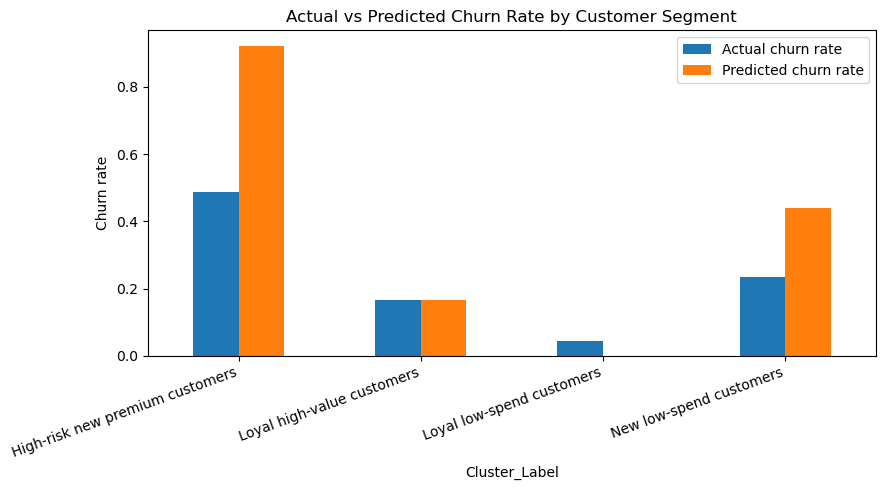

In [50]:
# Plot actual versus predicted churn rate by segment
plot_df = cluster_performance.set_index('Cluster_Label')[['Actual churn rate', 'Predicted churn rate']]
plot_df.plot(kind='bar', figsize=(9, 5))
plt.ylabel('Churn rate')
plt.title('Actual vs Predicted Churn Rate by Customer Segment')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('churn_by_segment.png', dpi=150, bbox_inches='tight')
plt.show()

In [51]:
# Save the results table for the final report
results_test.to_csv('test_predictions_with_clusters.csv', index=False)

### Final Model and Segment Analysis Notes

We saved the final model as churn_ann_model_final.keras and attached its predictions and churn probabilities to the test set, along with each customer's cluster from the earlier segmentation. We then checked how the model performs inside each segment.

The model performed best on the high-risk new premium customers. Recall within this segment was 0.97, so it caught 200 of the 207 customers who actually churned. It also flagged 92% of the segment as likely churners against an actual rate of 49%, so it casts a wide net, and about half of the customers it flagged (200 of 391) were genuine churners. This is the segment where retention effort should be focused first.

The model also worked reasonably well for new low-spend customers, with recall of 0.80, catching 62 of the 78 churners. It over-predicted churn, at 44% predicted against 23% actual, which is expected because we trained with class weighting to favour recall.

The model performed poorly for loyal high-value customers. Recall within this segment was only 0.41, so it missed 38 of the 64 churners in a group that pays the highest monthly charges. For loyal low-spend customers the model predicted no churners at all, although this segment is small, with only 9 actual churners in the test set. These two groups have long tenure, and the customers who leave from them do not look unusual on the features available to the model. Our dataset contains no usage, complaint, or billing history data that might explain why a long-standing customer leaves.

This links the two parts of the project. The clustering shows which groups carry the most churn risk, and the model gives each individual customer a churn probability. Together they support a strategic view (which segments to prioritise) and an operational one (which customers to contact first). The weak recall in the loyal high-value segment is a limitation we will document in the final report, along with possible solutions such as a lower threshold for this segment or collecting richer customer data.

## 17.0 Results summary across all models

In [52]:
# One table with the headline results for every model, so the notes can be checked against the actual run
def summarise(name, y_true, proba, threshold=0.5):
    proba = np.asarray(proba).ravel()
    pred = (proba > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, pred),
        'Precision (Churn)': precision_score(y_true, pred),
        'Recall (Churn)': recall_score(y_true, pred),
        'F1 (Churn)': f1_score(y_true, pred),
        'ROC-AUC': roc_auc_score(y_true, proba),
        'Churners caught': tp,
        'Churners missed': fn,
        'False alarms': fp
    }

model_summary = pd.DataFrame([
    summarise('Tuned, no class weights', y_test, y_pred_proba),
    summarise('Class-weighted', y_test, y_pred_proba_weighted),
    summarise('Grid search best (final)', y_test, y_pred_proba_best),
]).round(3)

model_summary.to_csv('model_results_summary.csv', index=False)
model_summary

,Model,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC,Churners caught,Churners missed,False alarms
0,"Tuned, no class weights",0.790,0.648,0.458,0.537,0.818,164,194,89
1,Class-weighted,0.732,0.496,0.788,0.609,0.819,282,76,286
2,Grid search best (final),0.715,0.478,0.804,0.600,0.816,288,70,314


### Results Summary Notes

The table puts the three models side by side on the same test set. The model without class weights has the highest accuracy and precision, but it misses more than half of the churners. Adding class weights moves recall from 0.46 to about 0.79. The grid search model is close to the class-weighted model on every measure. ROC-AUC barely changes across the three models (0.816 to 0.819), which tells us that class weighting mainly moves the decision point toward catching more churners, and does not give the model a better ability to rank customers by risk.

### Final Model Summary

Our final model is the class-weighted ANN selected through grid search, saved as churn_ann_model_final.keras. We use the default 0.5 classification threshold.

**Architecture**

The model is a sequential neural network with two hidden layers, 16 neurons in the first and 8 in the second, both using ReLU activation. Dropout of 0.3 follows the first hidden layer and 0.2 follows the second, to reduce overfitting. The output layer has a single neuron with sigmoid activation, giving a churn probability between 0 and 1. We trained with the Adam optimiser at a learning rate of 0.0005, binary crossentropy loss, a batch size of 64, class weighting, and early stopping on validation loss. Training stopped after 43 epochs, with the best weights from epoch 33.

**How we got here**

Our baseline model trained for 50 fixed epochs and showed mild overfitting. Training accuracy reached about 80%, but validation accuracy peaked at about 78.7% around epoch 18 and then drifted down, and the gap between training and validation loss widened slightly. We added dropout and early stopping, which gave stable convergence.

The tuned model reached 79% accuracy on the test set, but recall on the churn class was only 46%. Because churn is imbalanced, accuracy was hiding the fact that the model missed 194 of the 358 churners. We applied class weighting, which raised recall to about 79% at the cost of lower precision and accuracy. We accepted this trade-off deliberately. Missing a customer who is about to churn costs the business that customer entirely, while a false alarm only costs an unnecessary retention offer.

We then checked the classification threshold. The F1-optimal value was about 0.52, close to the default with only a tiny gain, so we kept 0.5. Finally, we ran a grid search over layer sizes, dropout, learning rate, and batch size, using a validation split from the training data only. The best configuration was only slightly ahead of the others, so the model is not very sensitive to these settings. On the test set the grid search model was very close to the class-weighted model. It caught slightly more churners but scored slightly lower on accuracy, precision, F1 and ROC-AUC. We kept it as the final model because it was selected using validation data and our priority is catching churners, and we do not describe it as clearly better.

**Final metrics on the test set**

| Metric | Value |
|---|---|
| Accuracy | 0.715 |
| Precision (Churn) | 0.478 |
| Recall (Churn) | 0.804 |
| F1 Score (Churn) | 0.600 |
| ROC-AUC | 0.816 |

**Performance by customer segment**

The model identified 97% of churners in the high-risk new premium segment and 80% in the new low-spend segment, but only 41% in the loyal high-value segment and none in the small loyal low-spend segment, where churners are harder to distinguish using the features available.

## STAGE 3 DELIVERABLES

In [53]:
os.makedirs('Predictive_Modeling', exist_ok=True)

# Save the final model inside the deliverable folder
model_best.save('Predictive_Modeling/churn_ann_model_final.keras')
print("Model saved.")

Model saved.


In [54]:
# Reload the saved model and confirm it gives the same predictions as the trained one
loaded_model = keras.models.load_model('Predictive_Modeling/churn_ann_model_final.keras')

same = np.allclose(loaded_model.predict(X_test, verbose=0), model_best.predict(X_test, verbose=0))
print("Saved model gives the same predictions as the trained model:", same)

Saved model gives the same predictions as the trained model: True


In [55]:
# Build a plain table of the architecture for the documentation
arch_rows = [{
    'Layer': 'input',
    'Type': 'Input',
    'Output shape': f"(None, {X_train.shape[1]})",
    'Activation': '',
    'Dropout rate': '',
    'Parameters': 0
}]

for layer in model_best.layers:
    arch_rows.append({
        'Layer': layer.name,
        'Type': layer.__class__.__name__,
        'Output shape': str(layer.output.shape),
        'Activation': layer.activation.__name__ if hasattr(layer, 'activation') else '',
        'Dropout rate': layer.rate if layer.__class__.__name__ == 'Dropout' else '',
        'Parameters': layer.count_params()
    })

architecture_table = pd.DataFrame(arch_rows)
architecture_table.to_csv('Predictive_Modeling/model_architecture_table.csv', index=False)

print("Total parameters:", model_best.count_params())
architecture_table

Total parameters: 321


,Layer,Type,Output shape,Activation,Dropout rate,Parameters
0,input,Input,"(None, 10)",,,0
1,dense,Dense,"(None, 16)",relu,,176
2,dropout,Dropout,"(None, 16)",,0.3,0
3,dense_1,Dense,"(None, 8)",relu,,136
4,dropout_1,Dropout,"(None, 8)",,0.2,0
5,dense_2,Dense,"(None, 1)",sigmoid,,9


### Predictive Modeling Deliverables Setup Notes

We created a Predictive_Modeling folder for the Stage 3 deliverables, matching the structure required for submission. We saved the final ANN as churn_ann_model_final.keras inside it. This is the grid search model with 16 and 8 neurons in its two hidden layers.

We then reloaded the saved file and checked that it gives the same predictions as the model we trained in the notebook. This confirms the file can be used on its own without retraining.

We also exported a table of the model's architecture, with each layer's type, output shape, activation, dropout rate and number of parameters. This table will go into the architecture document.

In [58]:
import shutil

os.makedirs('Predictive_Modeling/evaluation', exist_ok=True)

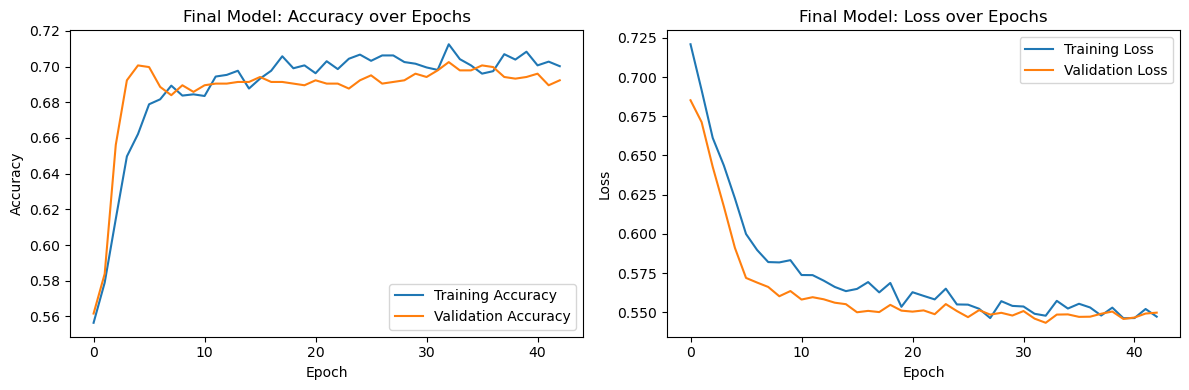

In [59]:
# Training curves for the final model
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_best.history['accuracy'], label='Training Accuracy')
plt.plot(history_best.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Final Model: Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_best.history['loss'], label='Training Loss')
plt.plot(history_best.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Final Model: Loss over Epochs')
plt.legend()

plt.tight_layout()
plt.savefig('Predictive_Modeling/evaluation/final_model_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

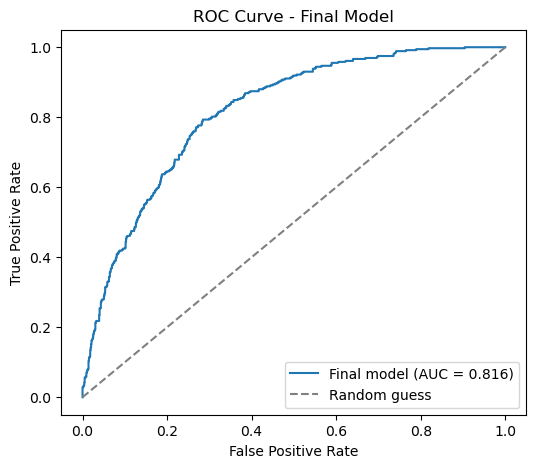

In [60]:
# ROC curve for the final model
auc_best = roc_auc_score(y_test, y_pred_proba_best)
fpr_b, tpr_b, _ = roc_curve(y_test, y_pred_proba_best)

plt.figure(figsize=(6, 5))
plt.plot(fpr_b, tpr_b, label=f'Final model (AUC = {auc_best:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Final Model')
plt.legend()
plt.savefig('Predictive_Modeling/evaluation/final_model_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [61]:
# Classification report for the final model, saved as text
report_text = classification_report(y_test, y_pred_best, target_names=['No Churn', 'Churn'])

with open('Predictive_Modeling/evaluation/final_model_classification_report.txt', 'w', encoding='utf-8') as f:
    f.write(report_text)

print(report_text)

              precision    recall  f1-score   support

    No Churn       0.91      0.68      0.78       991
       Churn       0.48      0.80      0.60       358

    accuracy                           0.72      1349
   macro avg       0.69      0.74      0.69      1349
weighted avg       0.79      0.72      0.73      1349



In [62]:
# Copy the evaluation plots and tables made earlier into the deliverable folder
files_to_copy = [
    'baseline_training_curves.png',
    'tuned_training_curves.png',
    'confusion_matrix.png',
    'confusion_matrix_weighted.png',
    'threshold_tuning.png',
    'confusion_matrix_optimal_threshold.png',
    'roc_curve.png',
    'confusion_matrix_grid_best.png',
    'churn_by_segment.png',
    'grid_search_results.csv',
    'model_results_summary.csv',
    'test_predictions_with_clusters.csv',
]

for f in files_to_copy:
    if os.path.exists(f):
        shutil.copy(f, 'Predictive_Modeling/evaluation/')
    else:
        print("Not found, check this one:", f)

print(sorted(os.listdir('Predictive_Modeling/evaluation')))

['baseline_training_curves.png', 'churn_by_segment.png', 'confusion_matrix.png', 'confusion_matrix_grid_best.png', 'confusion_matrix_optimal_threshold.png', 'confusion_matrix_weighted.png', 'final_model_classification_report.txt', 'final_model_roc_curve.png', 'final_model_training_curves.png', 'grid_search_results.csv', 'model_results_summary.csv', 'roc_curve.png', 'test_predictions_with_clusters.csv', 'threshold_tuning.png', 'tuned_training_curves.png']


### Evaluation Outputs Notes

We saved everything needed to review the model's performance in Predictive_Modeling/evaluation. This includes the training curves for the baseline, tuned and final models, the confusion matrices for each stage, the threshold tuning chart, the ROC curves, the grid search results, the side-by-side model comparison, and the test set predictions with each customer's segment attached.

For the final model we also saved its own training curves, ROC curve and classification report. On the test set it reached an ROC-AUC of 0.816, with recall of 0.80 for the churn class. Training stopped after 43 epochs, with the best weights taken from epoch 33.

## 18.0 Factors contributing to churn and retention

In [64]:
# Group the two Contract columns so Contract is measured as one factor
feature_groups = {
    'tenure': ['tenure'],
    'MonthlyCharges': ['MonthlyCharges'],
    'Contract': [c for c in X_test.columns if c.startswith('Contract_')],
    'InternetService': ['InternetService'],
    'MultipleLines': ['MultipleLines'],
    'PhoneService': ['PhoneService'],
    'Dependents': ['Dependents'],
    'SeniorCitizen': ['SeniorCitizen'],
    'gender': ['gender'],
}

baseline_auc = roc_auc_score(y_test, model_best.predict(X_test, verbose=0).ravel())
rng = np.random.default_rng(42)
n_repeats = 20

rows = []
for name, cols in feature_groups.items():
    drops = []
    for _ in range(n_repeats):
        X_shuffled = X_test.copy()
        order = rng.permutation(len(X_shuffled))
        X_shuffled[cols] = X_test[cols].values[order]   # shuffle these columns together
        auc_shuffled = roc_auc_score(y_test, model_best.predict(X_shuffled, verbose=0).ravel())
        drops.append(baseline_auc - auc_shuffled)
    rows.append({'Factor': name, 'AUC drop (mean)': np.mean(drops), 'AUC drop (std)': np.std(drops)})

importance = pd.DataFrame(rows).sort_values('AUC drop (mean)', ascending=False).reset_index(drop=True)
importance.to_csv('Predictive_Modeling/evaluation/factor_importance.csv', index=False)

print('Baseline AUC:', round(baseline_auc, 3))
display(importance.round(4))

Baseline AUC: 0.816


,Factor,AUC drop (mean),AUC drop (std)
0,tenure,0.2118,0.0143
1,MonthlyCharges,0.1188,0.0142
2,SeniorCitizen,0.0082,0.0013
3,Dependents,0.0035,0.0018
4,PhoneService,0.0030,0.0011
5,MultipleLines,0.0016,0.0014
6,Contract,0.0004,0.0015
7,InternetService,0.0001,0.0012
8,gender,-0.0005,0.0008


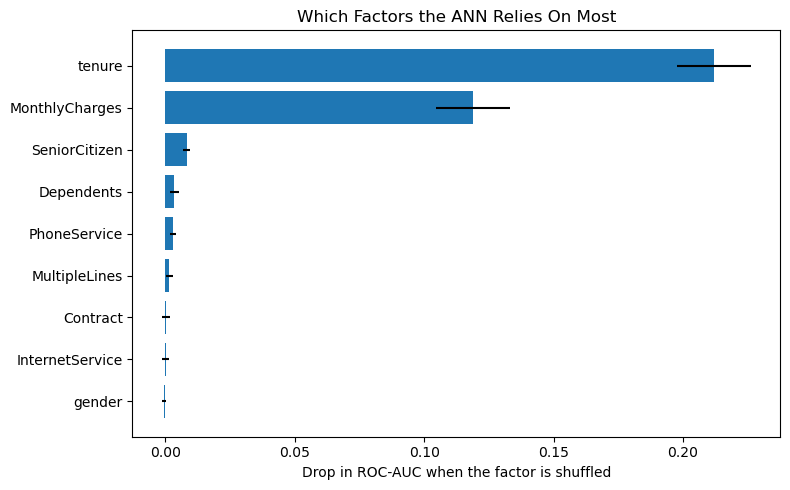

In [65]:
plot_df = importance.sort_values('AUC drop (mean)')
plt.figure(figsize=(8, 5))
plt.barh(plot_df['Factor'], plot_df['AUC drop (mean)'], xerr=plot_df['AUC drop (std)'], color='#1f77b4')
plt.xlabel('Drop in ROC-AUC when the factor is shuffled')
plt.title('Which Factors the ANN Relies On Most')
plt.tight_layout()
plt.savefig('Predictive_Modeling/evaluation/factor_importance.png', dpi=150, bbox_inches='tight')
plt.show()

### Factor Importance Notes

We measured which customer attributes the final ANN relies on using permutation importance on the test set. For each factor, we shuffled its values across the test customers so it carried no real information, and then measured how much the model's ROC-AUC dropped. A bigger drop means the model depends more on that factor. We repeated this 20 times per factor and averaged the results. The two Contract columns were shuffled together, so Contract is measured as one factor.

Tenure is by far the most important factor, with an average AUC drop of 0.21, followed by monthly charges at 0.12. Every other factor is much smaller. Senior citizen status (0.008), dependents (0.004) and phone service (0.003) have small effects. Multiple lines, contract type, internet service and gender are close to zero. Gender is slightly negative, which means shuffling it did not hurt the model at all, so we treat it as having no effect.

In practice, the ANN works mostly from how long a customer has stayed and how much they pay. This matches the clustering, where the segments were separated mainly by tenure and monthly charges. Permutation importance shows what the model relies on, and it does not prove what causes churn.

## 18.1 How churn varies across customer groups

In [66]:
# Use the whole customer base, with readable categories and the model's predicted probabilities
profile = df.copy()
profile['Actual_Churn'] = df_encoded['Churn']
profile['Predicted_Probability'] = model_best.predict(X, verbose=0).ravel()
profile['Flagged'] = (profile['Predicted_Probability'] > 0.5).astype(int)

profile['Tenure_Band'] = pd.cut(profile['tenure'], bins=[-1, 12, 24, 48, 72],
                                labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months'])
profile['Charge_Band'] = pd.cut(profile['MonthlyCharges'], bins=[0, 35, 65, 90, 120],
                                labels=['Up to 35', '36 to 65', '66 to 90', 'Over 90'])

def factor_table(col):
    t = profile.groupby(col, observed=True).agg(
        Customers=('Actual_Churn', 'size'),
        Actual_churn_rate=('Actual_Churn', 'mean'),
        Avg_predicted_probability=('Predicted_Probability', 'mean'),
        Flagged_as_churn=('Flagged', 'mean')
    ).round(3)
    t.insert(0, 'Factor', col)
    t.index = t.index.astype(str)
    return t

factors = ['Contract', 'Tenure_Band', 'Charge_Band', 'InternetService', 'MultipleLines',
           'SeniorCitizen', 'Dependents', 'PhoneService', 'gender']
factor_tables = {f: factor_table(f) for f in factors}

for f, t in factor_tables.items():
    print(f)
    display(t.drop(columns='Factor'))

pd.concat(factor_tables.values()).reset_index(names='Group').to_csv('Predictive_Modeling/evaluation/churn_by_factor.csv', index=False)

Contract


,Customers,Actual_churn_rate,Avg_predicted_probability,Flagged_as_churn
Contract,,,,
Month-to-month,3653,0.275,0.454,0.472
One year,1439,0.259,0.430,0.421
Two year,1649,0.252,0.413,0.401


Tenure_Band


,Customers,Actual_churn_rate,Avg_predicted_probability,Flagged_as_churn
Tenure_Band,,,,
0-12 months,1996,0.483,0.648,0.821
13-24 months,993,0.294,0.545,0.653
25-48 months,1570,0.206,0.404,0.392
49-72 months,2182,0.096,0.224,0.042


Charge_Band


...

,Customers,Actual_churn_rate,Avg_predicted_probability,Flagged_as_churn
Dependents,,,,
No,4690,0.313,0.494,0.540
Yes,2051,0.158,0.314,0.225


PhoneService


,Customers,Actual_churn_rate,Avg_predicted_probability,Flagged_as_churn
PhoneService,,,,
No,673,0.247,0.374,0.379
Yes,6068,0.268,0.446,0.451


gender


,Customers,Actual_churn_rate,Avg_predicted_probability,Flagged_as_churn
gender,,,,
Female,3348,0.271,0.449,0.453
Male,3393,0.261,0.429,0.435


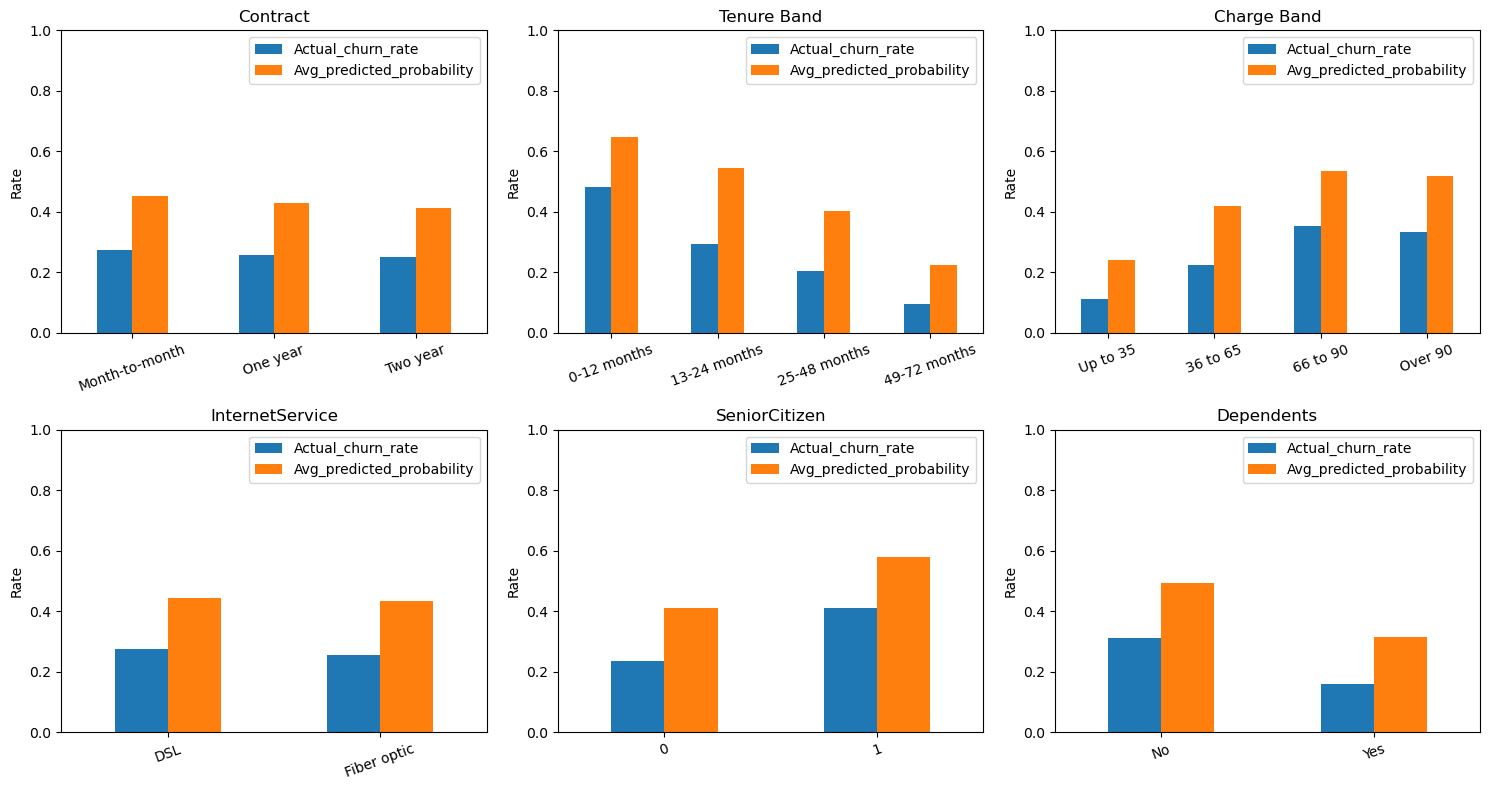

In [67]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), ['Contract', 'Tenure_Band', 'Charge_Band', 'InternetService', 'SeniorCitizen', 'Dependents']):
    t = factor_tables[f]
    t[['Actual_churn_rate', 'Avg_predicted_probability']].plot(kind='bar', ax=ax, rot=20)
    ax.set_title(f.replace('_', ' '))
    ax.set_xlabel('')
    ax.set_ylabel('Rate')
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('Predictive_Modeling/evaluation/churn_by_factor.png', dpi=150, bbox_inches='tight')
plt.show()

### Churn by Customer Factor Notes

We then looked at how churn varies across the main customer groups, using the whole customer base. For each group we compared the actual churn rate with the average churn probability predicted by the ANN. The predicted probabilities are higher than the actual rates in most groups because the model was trained with class weighting, so they should be read as risk scores for comparing groups and not as literal chances of churning.

Tenure shows the clearest pattern. Customers in their first 12 months churned at 48.3%, compared with 29.4% for 13 to 24 months, 20.6% for 25 to 48 months and 9.6% for customers with more than 48 months. The model follows this closely, with average predicted probability falling from 0.65 to 0.22. It flags 82% of first-year customers as likely churners, compared with 4% of those with more than 48 months.

Monthly charges also matter. Customers paying up to 35 churned at 11.2%, while those paying 66 to 90 churned at 35.4% and those paying over 90 at 33.3%. Churn rises with price up to about 66 and then levels off.

Senior citizens churned at 41.2%, compared with 23.6% for other customers. Customers without dependents churned at 31.3%, compared with 15.8% for customers with dependents.

Contract type, internet service, multiple lines, phone service and gender show little difference in actual churn, with all groups within about 3 percentage points of each other. For example, month-to-month customers churned at 27.5% and two-year customers at 25.2%. Contract length is often a strong churn driver in telecommunications, so this is unusual. We report it as a finding from this dataset and not as a general rule.

Putting this together, the customers most likely to leave are new, paying higher monthly charges, senior citizens, and without dependents. The customers most likely to stay have long tenure, lower charges and dependents.